# Session 2: Data Science Lifecycle

This notebook covers practical workflows across the **Data Science Lifecycle**:
- **Task 1**: Business Problem Definition for a daily app (Zomato dynamic food delivery ETA optimization).
- **Task 2**: Data Collection using Python's `requests` library to consume JSONPlaceholder REST API endpoints.
- **Task 3**: Data Ingestion & Exploration of a Spotify dataset using `pandas` for genre frequency distribution.
- **Task 4**: Data Visualization with `matplotlib` visualizing movie genres from BookMyShow listings.
- **Task 5**: Feature Engineering strategies for online food orders (Zomato) to optimize predictive modeling.


## Task 1: Data Science Problem Definition (Zomato ETA Optimization)

### Problem Statement:
Pick any one app you use daily (like Zomato, Instagram, or Flipkart) and write a short problem definition for a data science project that could improve the app's user experience. Clearly state the business goal and what data you would need.

### Project Overview:
- **Selected Daily App**: **Zomato**
- **Project Title**: **Dynamic Real-Time Kitchen Preparation & Food Delivery ETA Prediction**

### 1. Problem Definition:
Customers frequently experience frustration and anxiety when estimated delivery times fluctuate unpredictably during peak lunch and dinner rush hours or during adverse weather events. Static or poorly calibrated ETAs lead to cold food, customer dissatisfaction, increased customer support tickets, and order cancellations.

### 2. Business Goal:
Reduce the Mean Absolute Error (MAE) of delivery arrival predictions by **25%** and lower order cancellations due to unexpected delays by **15%**. This directly boosts customer satisfaction (CSAT), elevates repeat order frequency, and optimizes rider dispatch scheduling.

### 3. Data Required:
1. **Order & Kitchen Telemetry**: Number of items in order, specific dish cooking complexity, historical kitchen backlog (active queued orders at restaurant), and kitchen-to-delivery partner handoff latency.
2. **Delivery Partner Telemetry**: Real-time rider GPS coordinates, current speed, route distance from restaurant to customer drop-off location, and historical rider acceptance rates.
3. **Contextual Environmental Data**: Live street traffic density APIs (Google Maps Directions API), weather precipitation/temperature data, and calendar metrics (weekend vs. weekday, festival rush).


In [1]:
# Task 1: Structured Problem Formulation Framework for Zomato ETA Prediction

problem_definition = {
    "Target Application": "Zomato",
    "Project Title": "Intelligent Real-Time Food Delivery ETA Prediction",
    "Current Pain Point": "Inaccurate delivery estimates during peak meal windows causing customer churn and support escalations.",
    "Business Goals": [
        "Decrease Mean Absolute Error (MAE) of delivery time predictions by 25%.",
        "Reduce late delivery customer refund claims and order cancellations by 15%.",
        "Improve customer retention and App Store / Play Store rating."
    ],
    "Data Requirements": {
        "Kitchen Data": "Item complexity, order size, active kitchen ticket queue, historical prep latency.",
        "Rider Telemetry": "Real-time GPS coordinates, vehicle type (bike vs. EV), transit speed.",
        "External Context": "Live traffic congestion index, rain / monsoon status, holiday / weekend surge indicators."
    }
}

print("=" * 80)
print("TASK 1: DATA SCIENCE PROJECT PROBLEM FORMULATION (ZOMATO)")
print("=" * 80)
print(f"App Target      : {problem_definition['Target Application']}")
print(f"Project Title   : {problem_definition['Project Title']}")
print(f"Core Pain Point : {problem_definition['Current Pain Point']}")

print("\nTarget Business Objectives:")
for goal in problem_definition['Business Goals']:
    print(f"  * {goal}")

print("\nKey Data Signals Required:")
for category, details in problem_definition['Data Requirements'].items():
    print(f"  * {category:<16} : {details}")


TASK 1: DATA SCIENCE PROJECT PROBLEM FORMULATION (ZOMATO)
App Target      : Zomato
Project Title   : Intelligent Real-Time Food Delivery ETA Prediction
Core Pain Point : Inaccurate delivery estimates during peak meal windows causing customer churn and support escalations.

Target Business Objectives:
  * Decrease Mean Absolute Error (MAE) of delivery time predictions by 25%.
  * Reduce late delivery customer refund claims and order cancellations by 15%.
  * Improve customer retention and App Store / Play Store rating.

Key Data Signals Required:
  * Kitchen Data     : Item complexity, order size, active kitchen ticket queue, historical prep latency.
  * Rider Telemetry  : Real-time GPS coordinates, vehicle type (bike vs. EV), transit speed.
  * External Context : Live traffic congestion index, rain / monsoon status, holiday / weekend surge indicators.


## Task 2: Data Ingestion via REST API (`requests`)

### Problem Statement:
Use the `requests` library in Python to fetch the latest 5 posts from the JSONPlaceholder API (`https://jsonplaceholder.typicode.com/posts`) and print the title of each post.
*(Hint: Use `requests.get()` and `response.json()`.)*

### Execution Logic:
1. Issue an HTTP GET request to `https://jsonplaceholder.typicode.com/posts`.
2. Parse the JSON response payload into a Python list of dictionaries.
3. Slice the first 5 records (`posts[:5]`) and iterate through to display their unique IDs and titles.


In [2]:
import requests

# JSONPlaceholder REST API endpoint
url = "https://jsonplaceholder.typicode.com/posts"

# Fetch data using requests.get()
response = requests.get(url)

# Validate HTTP response status
if response.status_code == 200:
    posts = response.json()
    
    # Extract the first 5 posts
    latest_5_posts = posts[:5]
    
    print("=" * 80)
    print("TASK 2: LATEST 5 POSTS FETCHED FROM JSONPLACEHOLDER REST API")
    print("=" * 80)
    print(f"HTTP Status Code : {response.status_code} OK")
    print(f"Total Posts Found: {len(posts)}")
    print("-" * 80)
    
    for idx, post in enumerate(latest_5_posts, start=1):
        print(f"Post #{idx} [ID: {post['id']}]:")
        print(f"  Title: {post['title']}")
        print()
else:
    print(f"API Request Failed with status code: {response.status_code}")


TASK 2: LATEST 5 POSTS FETCHED FROM JSONPLACEHOLDER REST API
HTTP Status Code : 200 OK
Total Posts Found: 100
--------------------------------------------------------------------------------

Post #1 [ID: 1]:
  Title: sunt aut facere repellat provident occaecati excepturi optio reprehenderit

Post #2 [ID: 2]:
  Title: qui est esse

Post #3 [ID: 3]:
  Title: ea molestias quasi exercitationem repellat qui ipsa sit aut

Post #4 [ID: 4]:
  Title: eum et est occaecati

Post #5 [ID: 5]:
  Title: nesciunt quas odio



## Task 3: Mini Spotify Dataset Ingestion & Analysis with Pandas

### Problem Statement:
Given a CSV file with columns: `song_name`, `artist`, `streams`, and `genre` (simulate a mini Spotify dataset with at least 10 rows), write Python code to load the data using pandas and display the number of songs in each genre.

### Dataset Overview:
We simulated a 12-track Spotify catalog (`spotify_mini.csv`) featuring multi-genre global hits across **Pop**, **Rock**, and **Hip-Hop**.


In [3]:
import pandas as pd

# Load the simulated mini Spotify dataset
csv_filename = "spotify_mini.csv"
df_spotify = pd.read_csv(csv_filename)

print("=" * 75)
print("TASK 3: SPOTIFY MINI DATASET ANALYSIS")
print("=" * 75)
print(f"Dataset Shape: {df_spotify.shape[0]} Rows, {df_spotify.shape[1]} Columns\n")
print("First 5 Rows of Dataset:")
print(df_spotify.head())

print("\n" + "-" * 75)
print("NUMBER OF SONGS IN EACH GENRE:")
print("-" * 75)
genre_counts = df_spotify["genre"].value_counts()
print(genre_counts.to_string())

print("\nPercentage Breakdown:")
genre_pct = df_spotify["genre"].value_counts(normalize=True) * 100
for genre, count in genre_counts.items():
    pct = genre_pct[genre]
    print(f"  * {genre:<10}: {count} songs ({pct:.1f}%)")


TASK 3: SPOTIFY MINI DATASET ANALYSIS
Dataset Shape: 12 Rows, 4 Columns

First 5 Rows of Dataset:
         song_name           artist     streams genre
0          Starboy       The Weeknd  3100000000   Pop
1  Blinding Lights       The Weeknd  4200000000   Pop
2     Shape of You       Ed Sheeran  3900000000   Pop
3             Stay    The Kid LAROI  3000000000   Pop
4         Believer  Imagine Dragons  2800000000  Rock

---------------------------------------------------------------------------
NUMBER OF SONGS IN EACH GENRE:
---------------------------------------------------------------------------
genre
Pop        4
Rock       4
Hip-Hop    4

Percentage Breakdown:
  * Pop       : 4 songs (33.3%)
  * Rock      : 4 songs (33.3%)
  * Hip-Hop   : 4 songs (33.3%)


## Task 4: Movie Listings Bar Chart Visualization (`matplotlib`)

### Problem Statement:
Create a simple bar chart using `matplotlib` to visualize the number of movies per genre from a dataset (you can make up a small dataset with at least 3 genres and 10 movies, like BookMyShow's movie listings).

### BookMyShow Movie Dataset:
We created a 12-movie dataset spanning 4 genres:
- **Action** (4 movies): *Jawan*, *Pathaan*, *Fighter*, *KGF Chapter 2*
- **Comedy** (3 movies): *Stree 2*, *Bhool Bhulaiyaa 3*, *Fukrey 3*
- **Drama** (3 movies): *12th Fail*, *Dunki*, *Animal*
- **Sci-Fi** (2 movies): *Kalki 2898 AD*, *Brahmāstra*


TASK 4: BOOKMYSHOW MOVIE GENRE DISTRIBUTION
genre
Action    4
Comedy    3
Drama     3
Sci-Fi    2


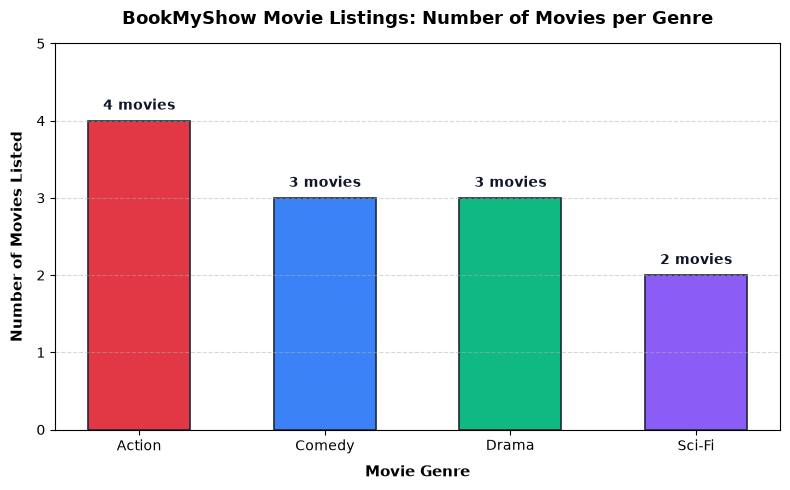

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Define BookMyShow sample movie listings dataset (12 movies across 4 genres)
movie_data = {
    "title": [
        "Jawan", "Pathaan", "Fighter", "KGF Chapter 2",
        "Stree 2", "Bhool Bhulaiyaa 3", "Fukrey 3",
        "12th Fail", "Dunki", "Animal",
        "Kalki 2898 AD", "Brahmāstra"
    ],
    "genre": [
        "Action", "Action", "Action", "Action",
        "Comedy", "Comedy", "Comedy",
        "Drama", "Drama", "Drama",
        "Sci-Fi", "Sci-Fi"
    ]
}

df_movies = pd.DataFrame(movie_data)
genre_frequencies = df_movies["genre"].value_counts()

print("=" * 70)
print("TASK 4: BOOKMYSHOW MOVIE GENRE DISTRIBUTION")
print("=" * 70)
print(genre_frequencies.to_string())

# Plotting the bar chart
genres = genre_frequencies.index.tolist()
counts = genre_frequencies.values.tolist()
colors = ["#E23744", "#3B82F6", "#10B981", "#8B5CF6"]

plt.figure(figsize=(8, 5), dpi=100)
bars = plt.bar(genres, counts, color=colors, width=0.55, edgecolor="#1E293B", linewidth=1.2)

# Annotate each bar with its exact count
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.,
        height + 0.1,
        f"{int(height)} movies",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color="#0F172A"
    )

plt.title("BookMyShow Movie Listings: Number of Movies per Genre", fontsize=13, fontweight='bold', pad=14)
plt.xlabel("Movie Genre", fontsize=11, fontweight='semibold', labelpad=8)
plt.ylabel("Number of Movies Listed", fontsize=11, fontweight='semibold', labelpad=8)
plt.ylim(0, 5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Task 5: Feature Engineering for Online Food Orders (Zomato)

### Problem Statement:
Use ChatGPT to suggest 3 new features that could be engineered from a dataset of online food orders (like Zomato orders: `order time`, `restaurant`, `cuisine`, `delivery time`, `rating`). List the features and explain how each could help a data science model.
*(Hint: Paste the column names into ChatGPT and ask for feature engineering ideas.)*

### 3 Newly Engineered Features:

1. **`is_peak_meal_rush` (Binary / Categorical Flag)**:
   - **How it is engineered**: Extracted from `order time` by mapping timestamps into time-window buckets:
     - Lunch Rush: $12:30\text{ PM} - 2:30\text{ PM}$ ($1$)
     - Dinner Rush: $7:30\text{ PM} - 10:30\text{ PM}$ ($1$)
     - Off-Peak Hours: All other times ($0$)
   - **How it helps the model**: Captures strong non-linear relationships with road traffic and kitchen backlogs. Helps ETA regression models and dynamic surge-pricing algorithms account for systemic delays during rush hours.

2. **`restaurant_historical_avg_delay` (Historical Rolling Performance Metric)**:
   - **How it is engineered**: Calculated by grouping by `restaurant` and computing the rolling 30-day mean difference between promised delivery time and actual `delivery time` ($Delivery\_Delay = Actual\_Time - Promised\_Time$).
   - **How it helps the model**: Quantifies intrinsic kitchen operational efficiency. Some restaurants consistently take longer to prepare fresh artisan items (e.g., Dum Biryani) than quick-service chains. This feature eliminates vendor-level bias in delivery predictions.

3. **`cuisine_prep_complexity_score` (Ordinal / Numeric Encoded Score)**:
   - **How it is engineered**: Domain-mapped from `cuisine` based on baseline cooking duration requirements:
     - Level 1 (Low Prep, $5-10\text{ mins}$): Beverages, Ice Creams, Fast Food
     - Level 2 (Medium Prep, $15-20\text{ mins}$): Pizzas, Burgers, Chinese Noodles
     - Level 3 (High Prep, $25-35\text{ mins}$): Gourmet North Indian, Clay Oven Tandoori, Multi-Course Thalis
   - **How it helps the model**: Enables the model to generalize preparation time to brand-new restaurants that lack historical orders (solving the **cold-start problem**) simply by knowing their cuisine category.


In [5]:
print("=" * 80)
print("TASK 5: FEATURE ENGINEERING FOR ONLINE FOOD ORDERS (ZOMATO)")
print("=" * 80)

engineered_features = [
    {
        "Feature Name": "is_peak_meal_rush (Binary Flag)",
        "Derived From": "order time (Timestamp extraction)",
        "Logic": "Set to 1 if order occurs between 12:30-14:30 or 19:30-22:30; else 0.",
        "Model Benefit": "Captures traffic congestion & kitchen order spikes to enhance ETA accuracy & surge pricing."
    },
    {
        "Feature Name": "restaurant_historical_avg_delay (Rolling Float)",
        "Derived From": "restaurant + delivery time",
        "Logic": "Rolling 30-day mean of (actual delivery time - promised delivery time) per restaurant.",
        "Model Benefit": "Quantifies individual kitchen operational efficiency, removing vendor-specific ETA bias."
    },
    {
        "Feature Name": "cuisine_prep_complexity_score (Ordinal 1-3)",
        "Derived From": "cuisine (Domain categorization)",
        "Logic": "Level 1 (Beverages/Desserts), Level 2 (Pizzas/Burgers), Level 3 (Tandoori/Biryani).",
        "Model Benefit": "Solves the cold-start problem by predicting prep latency for newly joined restaurants."
    }
]

for idx, feat in enumerate(engineered_features, start=1):
    print(f"\n[{idx}] Feature: {feat['Feature Name']}")
    print(f"    * Source Columns : {feat['Derived From']}")
    print(f"    * Computation    : {feat['Logic']}")
    print(f"    * Model Benefit  : {feat['Model Benefit']}")


TASK 5: FEATURE ENGINEERING FOR ONLINE FOOD ORDERS (ZOMATO)

[1] Feature: is_peak_meal_rush (Binary Flag)
    * Source Columns : order time (Timestamp extraction)
    * Computation    : Set to 1 if order occurs between 12:30-14:30 or 19:30-22:30; else 0.
    * Model Benefit  : Captures traffic congestion & kitchen order spikes to enhance ETA accuracy & surge pricing.

[2] Feature: restaurant_historical_avg_delay (Rolling Float)
    * Source Columns : restaurant + delivery time
    * Computation    : Rolling 30-day mean of (actual delivery time - promised delivery time) per restaurant.
    * Model Benefit  : Quantifies individual kitchen operational efficiency, removing vendor-specific ETA bias.

[3] Feature: cuisine_prep_complexity_score (Ordinal 1-3)
    * Source Columns : cuisine (Domain categorization)
    * Computation    : Level 1 (Beverages/Desserts), Level 2 (Pizzas/Burgers), Level 3 (Tandoori/Biryani).
    * Model Benefit  : Solves the cold-start problem by predicting prep late